# How many people do I need to find an effect? A Monte Carlo power simulation for a regression discontinuity on Dakar's BRT social fare

**Author:** Calvin Pan
**Date created:** October 31, 2026
**Date last modified:** October 31, 2026

---

This project was created as an assignment (Challenge #3) for my Impact Evaluations class (LPPA 7220) in UVA Batten's Master of Public Policy program. It's a power simulation for my class project.

On September 7th, CETUD (Dakar's transportation authority) rolled out a 50% discount on the BRT for people who are on Senegal's national poverty registry (RNU) and fall into one of 6 categories (above 60, below 15, below 25 & a student, female head of household, unemployed, or disabled). For my project, I'm planning to run regression discontinuities at the age thresholds: e.g. people just below 60 (not eligible) vs. just above 60 (eligible). My identifying assumption is that people just under and just over a threshold would have ridden the BRT the same amount without a social fare.

**The central question of this notebook: how large does N have to be for me to find an effect of the social fare on BRT ridership?** I won't have CETUD's data until November, so I make up fake people whose true effect I know, run my RD on them hundreds of times, and count how often it finds the effect (that's the power). Then I keep increasing N until power reaches 80%.

I answer it for two data cases and three cutoffs:
- **Case A: full population data.** CETUD's data covers everyone with an ID-linked card whose age and RNU status I can see, whether or not they applied.
- **Case B: applicants only.** I only see people who applied for the social fare (what CETUD has promised me so far).
- **Cutoffs:** 60 (eligible above), 25 for students (eligible below), and 15 (eligible below).

**Design I'm simulating (fuzzy RD):**
- **Running variable:** age, centered at the cutoff (`x` = age − cutoff).
- **Instrument:** being on the eligible side of the cutoff.
- **Treatment:** actually getting the social fare (`social_fare`). It's fuzzy because not everyone eligible gets approved and gets their card (missing documents, slow approvals, or never applying), and approvers might feel sympathetic for someone who is 59 years and 340 days old and approve them anyway.
- **Outcome:** change in average weekly BRT rides, from the 6 months before the rollout to the ~2 months after.
- **Estimator:** the same local linear regression we used in class for the Halloween RD: a line on each side of the cutoff within a bandwidth, robust standard errors, and the fuzzy RD estimate = reduced form / first stage.

### NOTE: This notebook only uses simulated data, so it runs without anything from CETUD. It takes about 10 minutes to run.

Once I have the real data, the parameters in Section 3 should be swapped for real numbers. The CETUD data itself is anonymized but shouldn't go on GitHub, so `rawdata/` is in `.gitignore`.

Folder structure:

challenge3_dakar_rd_montecarlo/
                    -- challenge3_pan_dakar_rd_montecarlo.ipynb (this notebook)
                    -- rawdata (CETUD applications + ridership data later; gitignored)
                    -- output (tables + figures)

### 0. Install packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import os
import time
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)   # Tiny samples sometimes divide by zero (handled in fuzzy_rd); hide the warnings

### 1. Set directories

In [2]:
# Set directories
dir = "/Users/calvin/Library/Mobile Documents/com~apple~CloudDocs/Documents/Calvin/UVA/2026-27/LPPA_7220_Impact_Evals/python/impactevals/challenge3_dakar_rd_montecarlo/"
rawdata_dir = dir + "rawdata/"
output_dir = dir + "output/"

os.makedirs(rawdata_dir, exist_ok=True)
os.makedirs(output_dir, exist_ok=True)

rng = np.random.default_rng(7220)   # Impact eval seed

### 2. How the data should be structured
Whatever CETUD sends, I want to end up with **one row per person** for the RD. Getting there takes four raw tables:

| Table | One row per | Key columns |
|---|---|---|
| `applications` | social fare application | person ID (hashed national ID), date of birth, category applied under, on RNU (yes/no), application date, online or in person, decision, decision date, approver, card issue date |
| `cards` | fare card | card ID, person ID (if ID-linked), card type (regular or social fare), issue date |
| `trips` | tap at a validator | card ID, date & time, station, fare paid |
| `population` *(Case A only)* | ID-linked cardholder | person ID, date of birth, on RNU (yes/no), category if known |

From those, I build a **person-week panel** (person ID, week, rides, fares paid, share of rides at peak hours) by linking each trip to a person through `cards`. That way a person's old regular card and new social fare card count as the same person. Then I collapse it into the **analysis file**, one row per person:

| Column | Meaning |
|---|---|
| `x` | age on September 7, 2026 (launch day) minus the cutoff. Using a fixed date instead of age at application means people can't move themselves by waiting to apply |
| `above` | 1 if age ≥ cutoff (the running variable's side) |
| `social_fare` | 1 if they had a social fare card during the post-period |
| `pre` | average weekly rides, March 7 – September 6 (26 weeks) |
| `post` | average weekly rides, September 7 – November 1 (8 weeks) |
| `change` | `post` − `pre` (the outcome) |
| covariates | category, online/in person, gender, home station: for checking that people on each side of the cutoff look similar |

**What's different between the two cases:**
- **Case A (full population):** the sample is everyone with an ID-linked card who is on the RNU and in the right category (e.g. all RNU members aged 55–65). The post-period starts on launch day for everyone, since non-applicants don't have an application date. This needs CETUD's card data linked to the RNU, which probably needs the RNU agency's help. The big advantage: nobody chooses whether they're in the sample, so there's no pile-up of applicants above the cutoff. The big disadvantage: most eligible people never apply, so the first stage is small.
- **Case B (applicants only):** the sample is only people who applied and had an ID-linked card before applying. The first stage is much bigger (most eligible applicants get approved), but people choose whether to apply, so applicants just below the cutoff might be different from those just above (Section 8).

**Things to check in the real data before running anything:**
1. Can a person's old card be linked to their new social fare card? Without that link, I lose everyone's pre-period.
2. Do people under 15 even have ID-linked cards? I think national ID cards are only issued from age 15, which would mean almost nobody just below 15 has a pre-period. (I need to check this.)
3. The pre-period (March–September) includes school holidays and the post-period doesn't. That should hit both sides of the 15 and 25 cutoffs about equally, so the RD still works, but it makes the change in rides noisier for students and kids.

### 3. Parameters: what I'm assuming
Most of these are guesses until I get CETUD's data. Where I could, I based them on my APP interviews or on the literature.

**Shared across all cutoffs:**

| Parameter | Value | Where it comes from |
|---|---|---|
| `EFFECTS` | 20% and 30% more rides | A 50% discount with a fare elasticity of about −0.3 to −0.4 gives ~15–20% (Paulley et al. 2006; Litman 2004). Free fares raised trips 12% in Santiago (Bull et al. 2021). I don't search for 10%: it needed more than 2,000 people even in the best case in my first run |
| `PRE_WEEKS`, `POST_WEEKS` | 26 and 8 | My data: 6 months before the rollout, ~2 months after |
| `BANDWIDTH` | 3 years on each side | Same idea as the Halloween RD; I check other bandwidths in Section 9 |
| `POP_TAKE_UP` (Case A) | 5% or 30% of eligible people get the social fare | 5% is roughly where things are now: fewer than ~100 applications by the end of September (Macadou interview). 30% is where Bogotá was a year after launch (260,000 of 900,000 eligible people had applied) |
| `POP_SYMPATHY` (Case A) | 0.5% of ineligible people get it anyway | Guess |

**Different for each cutoff:** the cutoff number itself doesn't matter for power, but *the people around it* do. Four things change how many people I need:
1. **How much they ride.** People who barely ride give a noisier change in rides relative to the effect.
2. **How much their riding changes anyway** (`change_sd`). Kids and students have school holidays in the pre-period, so their riding should change more.
3. **The first stage.** Kids need a parent to apply and students need a student card, so fewer eligible applicants may end up with a card than seniors, who just need their ID.
4. **How lopsided the applicants are.** If almost all applicants are on the eligible side, there are few people on the other side to compare to.

On top of that, *how many people I'll actually have* (`realistic_n`) is very different by cutoff. My rough math for Case A: the RNU covers ~75,000 households in Dakar, so maybe ~500,000 people (if ~7 per household, a guess). If ~6% are within 5 years of 60, that's ~30,000 people, and if ~5% of them have an ID-linked BRT card, ~1,500. Kids under 15 mostly won't have ID-linked cards (see Section 2). For Case B, I guess ~50 ID-linked applicants near the 60 and 25 cutoffs by November (fewer than ~100 applications by the end of September, split across 6 categories) and ~10 near 15.

In [3]:
WINDOW = 5             # Simulate people within 5 years of the cutoff
PRE_WEEKS = 26         # 6 months of ridership before the rollout
POST_WEEKS = 8         # ~2 months after
BANDWIDTH = 3          # Years on each side of the cutoff used in the regression
SPREAD = 1.5           # How spread out riding is across people (lower = more spread out; some ride a lot, many ride a little)

EFFECTS = [0.2, 0.3]
POP_TAKE_UPS = [0.05, 0.3]
POP_SYMPATHY = 0.005

CUTOFFS = {
    60: {"label": "60+ (seniors)", "eligible_side": "above",
         "base_rides": 4, "age_slope": -0.03, "change_sd": 0.3,                       # Rides/week at the cutoff; older people ride a bit less
         "share_eligible_applicants": 0.75, "take_up_applicants": 0.8, "sympathy": 0.05,
         "realistic_n_population": 1500, "realistic_n_applicants": 50},
    25: {"label": "Under 25 (students)", "eligible_side": "below",
         "base_rides": 6, "age_slope": -0.02, "change_sd": 0.4,                       # Students commute more; school holidays make riding change more
         "share_eligible_applicants": 0.75, "take_up_applicants": 0.7, "sympathy": 0.05,
         "realistic_n_population": 1500, "realistic_n_applicants": 50},
    15: {"label": "Under 15 (kids)", "eligible_side": "below",
         "base_rides": 2, "age_slope": 0.05, "change_sd": 0.4,                        # Kids ride less, and older kids ride more
         "share_eligible_applicants": 0.75, "take_up_applicants": 0.6, "sympathy": 0.05,
         "realistic_n_population": 300, "realistic_n_applicants": 10},
}
pd.DataFrame(CUTOFFS).T

,label,eligible_side,base_rides,age_slope,change_sd,share_eligible_applicants,take_up_applicants,sympathy,realistic_n_population,realistic_n_applicants
60,60+ (seniors),above,4,-0.03,0.3,0.75,0.8,0.05,1500,50
25,Under 25 (students),below,6,-0.02,0.4,0.75,0.7,0.05,1500,50
15,Under 15 (kids),below,2,0.05,0.4,0.75,0.6,0.05,300,10


### 4. Simulate one fake dataset
Each fake person gets:
1. **An age.** In Case A ages are spread evenly around the cutoff (it's the whole population). In Case B 75% are on the eligible side, because people mostly apply once they're eligible.
2. **How much they normally ride.** Most people ride a little and a few ride a lot, so I draw this from a skewed (gamma) distribution with an average of `base_rides` per week at the cutoff.
3. **Weekly rides before the rollout,** counted over 26 weeks (a Poisson count around how much they normally ride).
4. **Whether they get the social fare.** Case A: `POP_TAKE_UP` if eligible, `POP_SYMPATHY` if not. Case B: `take_up_applicants` if eligible, `sympathy` if not.
5. **Weekly rides after the rollout** for 8 weeks. Their riding drifts a bit for other reasons (`change_sd`), and if they got the social fare, it goes up by `effect` (e.g. 0.2 = 20% more rides).

The outcome is the **change** in average weekly rides (after − before). Using the change instead of the level means that differences in how much people normally ride mostly cancel out. Section 8 shows why that matters.

`selection` is for Section 8: it makes ineligible applicants ride more than a typical person their age, to mimic heavy riders being the ones who apply even though they don't qualify.

In [4]:
def simulate(n, effect, cutoff, case, take_up=None, selection=0, change_sd=None, post_weeks=POST_WEEKS):
    p = CUTOFFS[cutoff]
    if case == "A":
        share_eligible, sympathy = 0.5, POP_SYMPATHY                       # Whole population: ages spread evenly around the cutoff
    else:
        share_eligible, sympathy = p["share_eligible_applicants"], p["sympathy"]
        take_up = p["take_up_applicants"] if take_up is None else take_up
    change_sd = p["change_sd"] if change_sd is None else change_sd

    # 1. Age, centered at the cutoff (x = age - cutoff). Eligible side depends on the cutoff
    eligible = rng.random(n) < share_eligible
    distance = rng.uniform(0, WINDOW, n)
    if p["eligible_side"] == "above":
        x = np.where(eligible, distance, -distance)
    else:
        x = np.where(eligible, -distance, distance)

    # 2. How much each person normally rides per week
    normal_rides = rng.gamma(SPREAD, p["base_rides"] / SPREAD, n) * np.exp(p["age_slope"] * x)
    normal_rides = np.where(eligible, normal_rides, normal_rides * np.exp(selection))   # Section 8: ineligible applicants ride more

    # 3. Average weekly rides before. (Adding up 26 weekly Poisson counts = one Poisson count with 26x the mean, which is much faster)
    pre = rng.poisson(normal_rides * PRE_WEEKS) / PRE_WEEKS

    # 4. Who gets the social fare
    social_fare = np.where(eligible, rng.random(n) < take_up, rng.random(n) < sympathy).astype(int)

    # 5. Average weekly rides after
    drift = rng.lognormal(-0.5 * change_sd**2, change_sd, n)          # Riding changes for other reasons; averages out to 1
    post = rng.poisson(normal_rides * drift * (1 + effect * social_fare) * post_weeks) / post_weeks

    return pd.DataFrame({"x": x, "age": cutoff + x, "above": (x >= 0).astype(int), "eligible": eligible.astype(int),
                         "social_fare": social_fare, "pre": pre, "post": post, "change": post - pre})

# Checks
fake = simulate(1000, effect=0.2, cutoff=60, case="B")
print(str(len(fake)) + " fake applicants")                                            # Should be 1000
print("Share eligible: " + str(round(fake["eligible"].mean(), 2)))                    # Should be ~0.75
print("Average weekly rides before: " + str(round(fake["pre"].mean(), 2)))            # Should be ~4
print(fake.groupby("eligible")["social_fare"].mean().round(2))                        # Should be ~0.05 ineligible, ~0.80 eligible
fake.head()

1000 fake applicants
Share eligible: 0.78
Average weekly rides before: 3.97
eligible
0    0.04
1    0.77
Name: social_fare, dtype: float64


,x,age,above,eligible,social_fare,pre,post,change
0,3.474901,63.474901,1,1,1,3.192308,3.125,-0.067308
1,2.182841,62.182841,1,1,1,2.461538,2.875,0.413462
2,-1.543781,58.456219,0,0,0,4.769231,5.625,0.855769
3,-0.919989,59.080011,0,0,0,5.384615,6.750,1.365385
4,-4.145482,55.854518,0,0,0,0.884615,0.500,-0.384615


#### Figure 1: How many people are at each age?
This is the density check from class, for the 60 cutoff. In Case A (whole population) there's no jump at 60. In Case B, people mostly apply once they're eligible, so I *expect* applications to pile up just above 60 even though nobody can fake their age. That pile-up is the selection problem in Section 8.

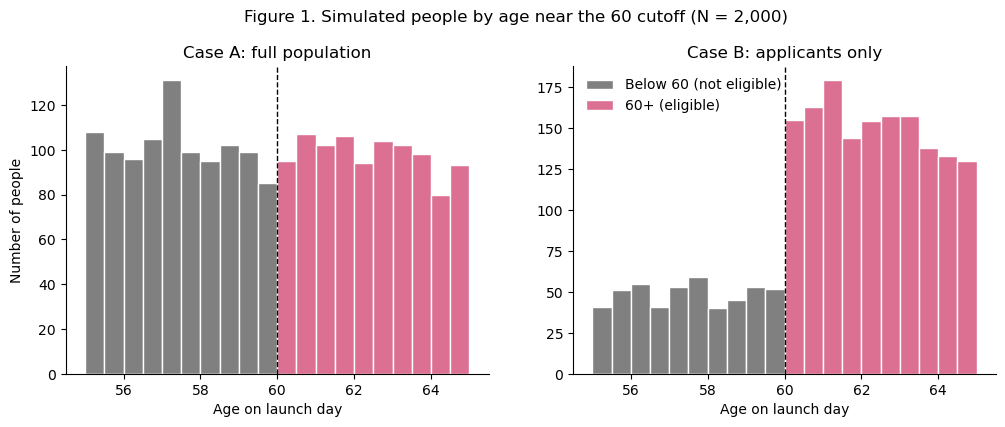

In [5]:
edges = np.arange(60 - WINDOW, 60 + WINDOW + 0.5, 0.5)   # Half-year bins that line up with the cutoff

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, case, title in zip(axes, ["A", "B"], ["Case A: full population", "Case B: applicants only"]):
    d = simulate(2000, effect=0.2, cutoff=60, case=case, take_up=0.3 if case == "A" else None)   # Case B uses the applicant take-up (80%)
    ax.hist(d.loc[d["above"] == 0, "age"], bins=edges, color="gray", edgecolor="white", label="Below 60 (not eligible)")
    ax.hist(d.loc[d["above"] == 1, "age"], bins=edges, color="palevioletred", edgecolor="white", label="60+ (eligible)")
    ax.axvline(60, color="black", linestyle="--", linewidth=1)
    ax.set_xlabel("Age on launch day")
    ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Number of people")
axes[1].legend(frameon=False)
fig.suptitle("Figure 1. Simulated people by age near the 60 cutoff (N = 2,000)", y=1.02)
plt.savefig(output_dir + "fig1_density_by_case.png", dpi=200, bbox_inches="tight")
plt.show()

#### Figure 2: First stage and reduced form
Same two pictures as the Halloween RD, for the 60 cutoff with N = 2,000 and a 20% effect. Each dot is the average for people in a half-year age bin, with a line fit on each side of the cutoff within the bandwidth.
- **First stage (left):** the share who got the social fare jumps at 60. The jump is small in Case A (30% take-up, since most eligible people never apply) and big in Case B (80%).
- **Reduced form (right):** the change in weekly rides jumps at 60 by the first-stage jump times the effect, so it's much harder to see in Case A.

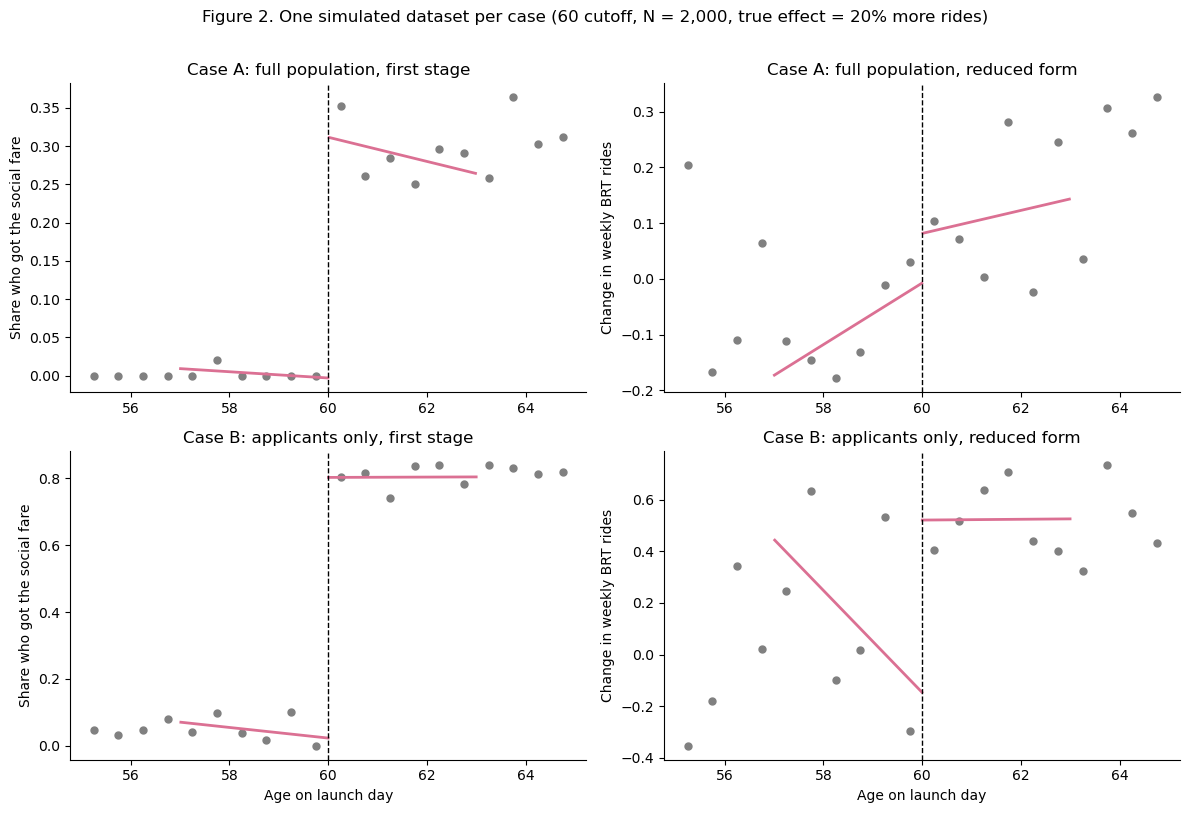

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, case in enumerate(["A", "B"]):
    d = simulate(2000, effect=0.2, cutoff=60, case=case, take_up=0.3 if case == "A" else None)   # Case B uses the applicant take-up (80%)
    d["bin"] = np.floor(d["age"] * 2) / 2 + 0.25      # Half-year bin midpoints
    binned = d.groupby("bin")[["social_fare", "change"]].mean()
    for col, (y, ylabel) in enumerate([("social_fare", "Share who got the social fare"), ("change", "Change in weekly BRT rides")]):
        ax = axes[row, col]
        ax.scatter(binned.index, binned[y], color="gray", s=25)
        for side in [0, 1]:
            s = d[(d["above"] == side) & (d["x"].abs() <= BANDWIDTH)]
            slope, intercept = np.polyfit(s["age"], s[y], 1)
            ages = np.array([s["age"].min(), s["age"].max()])
            ax.plot(ages, intercept + slope * ages, color="palevioletred", linewidth=2)
        ax.axvline(60, color="black", linestyle="--", linewidth=1)
        ax.set_ylabel(ylabel)
        ax.set_title(("Case A: full population" if case == "A" else "Case B: applicants only") + (", first stage" if col == 0 else ", reduced form"))
        ax.spines[["top", "right"]].set_visible(False)
for ax in axes[1]:
    ax.set_xlabel("Age on launch day")
fig.suptitle("Figure 2. One simulated dataset per case (60 cutoff, N = 2,000, true effect = 20% more rides)", y=1.01)
plt.tight_layout()
plt.savefig(output_dir + "fig2_first_stage_reduced_form.png", dpi=200, bbox_inches="tight")
plt.show()

### 5. Estimate the fuzzy RD on the fake data
Same steps as the Halloween RD in class, within the bandwidth:
1. **First stage:** regress `social_fare` on `above`, `x`, and `x_above` (so the slope can differ on each side). The coefficient on `above` is the jump in who gets the social fare. (For the 25 and 15 cutoffs, the eligible side is *below*, so this jump is negative. That's fine: the reduced form flips too, and the ratio comes out the same.)
2. **Reduced form:** the same regression with the change in rides as the outcome.
3. **Fuzzy RD (Wald) estimate** = reduced form / first stage. This is the effect of the social fare on rides for compliers: people who got it *because* they were on the eligible side.

**How I test whether there's an effect:** the fuzzy RD estimate is just the reduced form divided by the first stage, so it's zero exactly when the reduced form is zero. So I use the p-value on the reduced form jump to decide whether the social fare did anything. This avoids needing a 2SLS package, and it stays reliable even when the first stage is weak (which can happen with very few people, or a low take-up in Case A).

In [7]:
def fuzzy_rd(df, bandwidth=BANDWIDTH, outcome="change"):
    d = df[df["x"].abs() <= bandwidth]                                     # Only people within the bandwidth
    X = sm.add_constant(pd.DataFrame({"above": d["above"], "x": d["x"], "x_above": d["x"] * d["above"]}))
    first_stage = sm.OLS(d["social_fare"], X).fit(cov_type="HC1")        # Robust standard errors, like ", robust" in Stata
    reduced_form = sm.OLS(d[outcome], X).fit(cov_type="HC1")
    return {"first_stage": first_stage.params["above"],
            "reduced_form": reduced_form.params["above"],
            "wald": reduced_form.params["above"] / first_stage.params["above"] if first_stage.params["above"] != 0 else np.nan,   # No first stage = no estimate
            "p_value": reduced_form.pvalues["above"],
            "n_used": len(d)}

one_run = fuzzy_rd(fake)
print("People used (within " + str(BANDWIDTH) + " years): " + str(one_run["n_used"]))
print("First stage (jump in getting the social fare at 60): " + str(round(one_run["first_stage"], 3)))      # Should be ~0.75 (0.80 - 0.05)
print("Reduced form (jump in the change in weekly rides): " + str(round(one_run["reduced_form"], 3)))
print("Fuzzy RD estimate: " + str(round(one_run["wald"], 2)) + " more rides/week (truth: " + str(0.2 * CUTOFFS[60]["base_rides"]) + ")")
print("p-value: " + str(round(one_run["p_value"], 4)))

People used (within 3 years): 599
First stage (jump in getting the social fare at 60): 0.675
Reduced form (jump in the change in weekly rides): 0.381
Fuzzy RD estimate: 0.56 more rides/week (truth: 0.8)
p-value: 0.1788


### 6. The search: how large does N have to be?
For each case, cutoff, and effect size, I start at N = 50 and double N until the RD finds the effect at least 80% of the time:
1. Simulate `REPS_SEARCH` fake datasets of size N and run the fuzzy RD on each.
2. **Power** = the share of runs where p < 0.05.
3. If power is under 80%, double N and repeat. Once it passes 80%, I estimate the exact N between the last two tries (on a log scale).

N counts everyone within 5 years of the cutoff, and the regression uses the ones within 3 years (about 60% of them). I stop at `N_CAP`: if power still isn't 80% there, the answer is "more than that," which for my purposes means "not feasible."

I also check the **false positive rate** (power when the true effect is 0) at each cutoff's realistic N, since Section 7 of my first run showed it's too high with very small samples.

In [8]:
REPS_SEARCH = 200
N_START = 50
N_CAP = 409600         # 50 x 2^13

def power_at(n, effect, cutoff, case, take_up=None, reps=REPS_SEARCH):
    runs = pd.DataFrame([fuzzy_rd(simulate(n, effect, cutoff, case, take_up=take_up)) for r in range(reps)])
    return (runs["p_value"] < 0.05).mean(), runs["wald"].median()

def find_n_needed(effect, cutoff, case, take_up=None):
    curve = []
    n = N_START
    while n <= N_CAP:
        power, median_estimate = power_at(n, effect, cutoff, case, take_up)
        curve.append({"n": n, "power": power, "median_estimate": median_estimate})
        if power >= 0.8:
            break
        n = n * 2
    curve = pd.DataFrame(curve)
    if curve["power"].iloc[-1] < 0.8:
        n_needed = np.nan                                                     # Never reached 80% before the cap
    elif len(curve) == 1:
        n_needed = N_START
    else:
        lo, hi = curve.iloc[-2], curve.iloc[-1]                              # Estimate where power crosses 80% between the last two tries
        share = (0.8 - lo["power"]) / (hi["power"] - lo["power"])
        n_needed = np.exp(np.log(lo["n"]) + share * (np.log(hi["n"]) - np.log(lo["n"])))
    return n_needed, curve

def run_block(cutoff, case):
    # Searches every effect (and, for Case A, every take-up) for one cutoff
    rows, curves = [], []
    take_ups = POP_TAKE_UPS if case == "A" else [CUTOFFS[cutoff]["take_up_applicants"]]
    realistic_n = CUTOFFS[cutoff]["realistic_n_population" if case == "A" else "realistic_n_applicants"]
    for take_up in take_ups:
        false_positive, _ = power_at(max(realistic_n, 20), 0, cutoff, case, take_up)
        for effect in EFFECTS:
            n_needed, curve = find_n_needed(effect, cutoff, case, take_up)
            rows.append({"case": case, "cutoff": cutoff, "take_up": take_up, "effect": effect,
                         "N needed for 80% power": "> " + f"{N_CAP:,}" if np.isnan(n_needed) else f"{n_needed:,.0f}",
                         "n_needed": n_needed,
                         "my realistic N": realistic_n,
                         "false positive rate at realistic N": false_positive})
            curves.append(curve.assign(case=case, cutoff=cutoff, take_up=take_up, effect=effect))
    return pd.DataFrame(rows), pd.concat(curves)

all_results, all_curves = [], []
start = time.time()

### 7A. Case A: full population data
Here the sample is everyone with an ID-linked card on the RNU near the cutoff, whether or not they applied. The first stage is just the share of eligible people who ended up with a social fare, which I try at 5% (roughly now) and 30% (Bogotá after a year).

#### 7A.1 Cutoff 60 (eligible above)
Seniors ride a moderate amount and their riding is fairly stable, but this is the cutoff where retirement (60) and Plan Sésame health coverage (60+) also kick in. That doesn't change power, but it does threaten the RD itself.

In [9]:
table, curves = run_block(60, "A")
all_results.append(table); all_curves.append(curves)
table.drop(columns="n_needed")

,case,cutoff,take_up,effect,N needed for 80% power,my realistic N,false positive rate at realistic N
0,A,60,0.05,0.2,"> 409,600",1500,0.06
1,A,60,0.05,0.3,"244,533",1500,0.06
2,A,60,0.30,0.2,"14,703",1500,0.03
3,A,60,0.30,0.3,"6,052",1500,0.03


#### 7A.2 Cutoff 25, students (eligible below)
Students ride the most, which helps, but their riding changes more between the pre-period (with school holidays) and the post-period (school in session), which hurts.

In [10]:
table, curves = run_block(25, "A")
all_results.append(table); all_curves.append(curves)
table.drop(columns="n_needed")

,case,cutoff,take_up,effect,N needed for 80% power,my realistic N,false positive rate at realistic N
0,A,25,0.05,0.2,"> 409,600",1500,0.070
1,A,25,0.05,0.3,"374,557",1500,0.070
2,A,25,0.30,0.2,"22,045",1500,0.045
3,A,25,0.30,0.3,"9,969",1500,0.045


#### 7A.3 Cutoff 15 (eligible below)
Kids ride the least and their riding changes a lot, so I expect this cutoff to need the most people. On top of that, kids under 15 probably don't have ID-linked cards (Section 2), so the realistic N is tiny.

In [11]:
table, curves = run_block(15, "A")
all_results.append(table); all_curves.append(curves)
table.drop(columns="n_needed")

,case,cutoff,take_up,effect,N needed for 80% power,my realistic N,false positive rate at realistic N
0,A,15,0.05,0.2,"> 409,600",300,0.07
1,A,15,0.05,0.3,"> 409,600",300,0.07
2,A,15,0.30,0.2,"26,071",300,0.06
3,A,15,0.30,0.3,"11,193",300,0.06


### 7B. Case B: applicants only
Here the sample is only ID-linked applicants. The first stage is big (most eligible applicants get approved), but 75% of applicants are on the eligible side, so there are fewer people to compare against on the other side.

#### 7B.1 Cutoff 60 (eligible above)
Seniors only need their ID to prove their age, so I assume 80% of eligible applicants get the card.

In [12]:
table, curves = run_block(60, "B")
all_results.append(table); all_curves.append(curves)
table.drop(columns="n_needed")

,case,cutoff,take_up,effect,N needed for 80% power,my realistic N,false positive rate at realistic N
0,B,60,0.8,0.2,"3,259",50,0.14
1,B,60,0.8,0.3,"1,229",50,0.14


#### 7B.2 Cutoff 25, students (eligible below)
Students also need a student card, so I assume 70% get the social fare.

In [13]:
table, curves = run_block(25, "B")
all_results.append(table); all_curves.append(curves)
table.drop(columns="n_needed")

,case,cutoff,take_up,effect,N needed for 80% power,my realistic N,false positive rate at realistic N
0,B,25,0.7,0.2,"6,098",50,0.13
1,B,25,0.7,0.3,"2,898",50,0.13


#### 7B.3 Cutoff 15 (eligible below)
Kids need a parent to apply and proof of age, so I assume 60% get the social fare.

In [14]:
table, curves = run_block(15, "B")
all_results.append(table); all_curves.append(curves)
table.drop(columns="n_needed")

,case,cutoff,take_up,effect,N needed for 80% power,my realistic N,false positive rate at realistic N
0,B,15,0.6,0.2,"10,572",10,0.325
1,B,15,0.6,0.3,"4,485",10,0.325


#### Table 1: N needed for 80% power, everything in one place
Compare "N needed" to "my realistic N": if N needed is bigger, the RD can't find the effect with the data I'll have.

In [15]:
print("Search done in " + str(round((time.time() - start) / 60, 1)) + " minutes")
results = pd.concat(all_results, ignore_index=True)
curves = pd.concat(all_curves, ignore_index=True)
results.to_csv(output_dir + "table1_n_needed.csv", index=False)
curves.to_csv(output_dir + "table1b_power_curves.csv", index=False)

table1 = results.pivot_table(index=["case", "cutoff", "take_up", "my realistic N"], columns="effect",
                             values="N needed for 80% power", aggfunc="first")
table1.columns = ["N needed: +20% rides", "N needed: +30% rides"]
table1

Search done in 8.9 minutes


N needed: +20% rides N needed: +30% rides
case cutoff take_up my realistic N                                          
A    15     0.05    300                       > 409,600            > 409,600
            0.30    300                          26,071               11,193
     25     0.05    1500                      > 409,600              374,557
            0.30    1500                         22,045                9,969
     60     0.05    1500                      > 409,600              244,533
            0.30    1500                         14,703                6,052
B    15     0.60    10                           10,572                4,485
     25     0.70    50                            6,098                2,898
     60     0.80    50                            3,259                1,229

#### Figure 3: Power as N grows
Each panel is one case and cutoff. The dashed line is 80% power, and the dotted line is my guess at the realistic N. Where a line stops, power passed 80% (or N hit the cap).

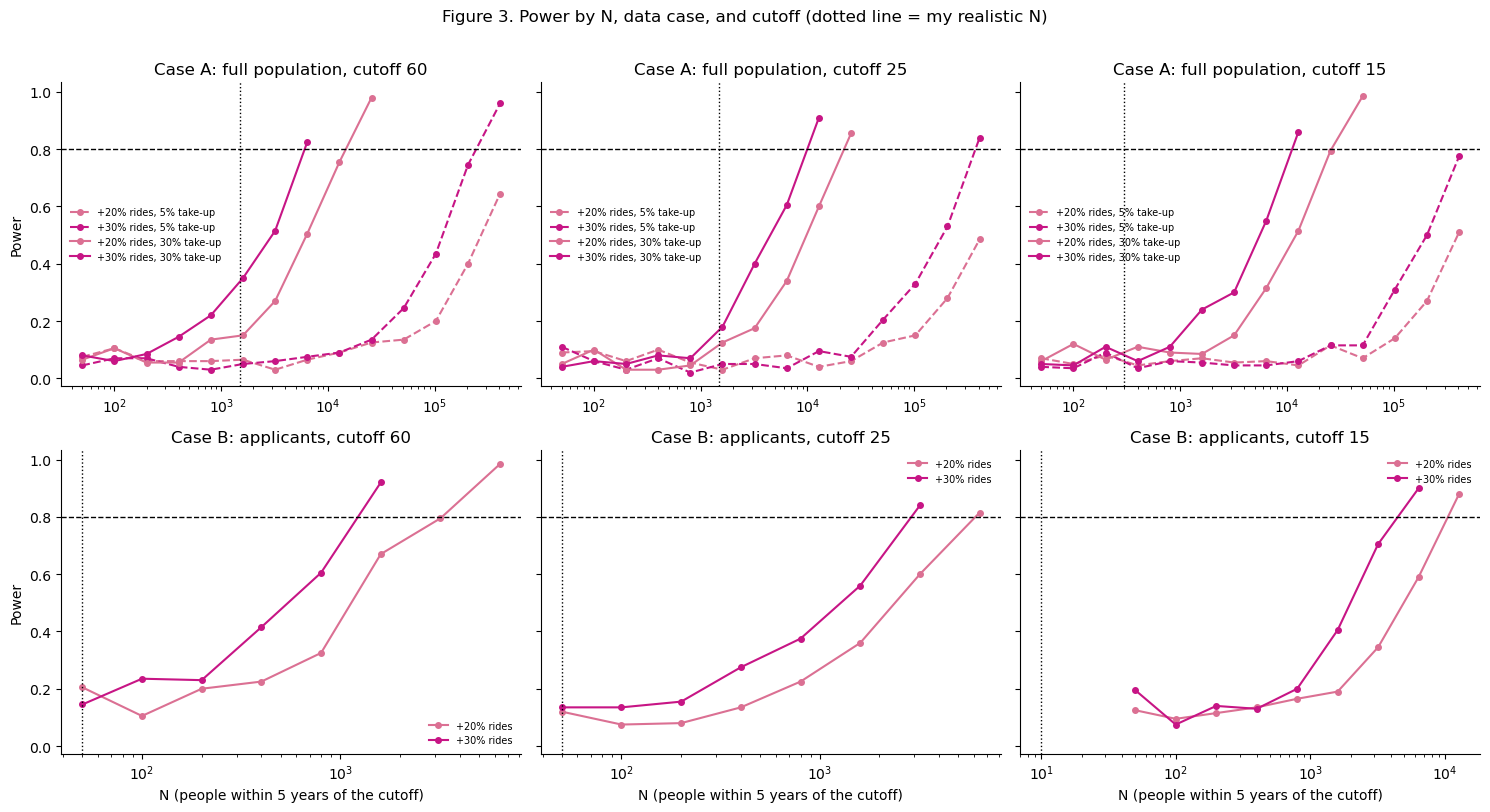

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
colors = {0.2: "palevioletred", 0.3: "mediumvioletred"}
for row, case in enumerate(["A", "B"]):
    for col, cutoff in enumerate([60, 25, 15]):
        ax = axes[row, col]
        d = curves[(curves["case"] == case) & (curves["cutoff"] == cutoff)]
        for (take_up, effect), g in d.groupby(["take_up", "effect"]):
            style = "--" if (case == "A" and take_up == 0.05) else "-"
            label = "+" + str(int(effect * 100)) + "% rides" + (", " + str(int(take_up * 100)) + "% take-up" if case == "A" else "")
            ax.plot(g["n"], g["power"], marker="o", markersize=4, linestyle=style, color=colors[effect], label=label)
        ax.axhline(0.8, color="black", linestyle="--", linewidth=1)
        ax.axvline(CUTOFFS[cutoff]["realistic_n_population" if case == "A" else "realistic_n_applicants"], color="black", linestyle=":", linewidth=1)
        ax.set_xscale("log")
        ax.set_title(("Case A: full population" if case == "A" else "Case B: applicants") + ", cutoff " + str(cutoff))
        ax.spines[["top", "right"]].set_visible(False)
        if row == 1:
            ax.set_xlabel("N (people within 5 years of the cutoff)")
        if col == 0:
            ax.set_ylabel("Power")
        ax.legend(frameon=False, fontsize=7)
fig.suptitle("Figure 3. Power by N, data case, and cutoff (dotted line = my realistic N)", y=1.01)
plt.tight_layout()
plt.savefig(output_dir + "fig3_power_by_case_cutoff.png", dpi=200, bbox_inches="tight")
plt.show()

### 8. Case B only: what if heavy riders are the ones who apply below the cutoff?
In the searches above, people on both sides of the cutoff are the same kind of people. But in real life, most 58- and 59-year-olds know they don't qualify and don't apply. The ones who apply anyway might be different: for example, heavy BRT riders who really want the discount. If so, the people just below the cutoff aren't a good comparison for the people just above it. (This can't happen in Case A, since nobody chooses to be in the sample.)

Here I make ineligible applicants ride 35% more than a typical person their age (`selection = 0.3`), and set the true effect to **zero**, at the 60 cutoff with 500 applicants. Then I compare two outcomes:
1. **Rides after the rollout (level).**
2. **Change in rides (after − before):** what I've been using.

If heavy riders select in, the level outcome should find a (fake) *negative* effect, since the comparison group below 60 rides more to begin with. The change outcome should mostly cancel that out, because each person is compared to their own riding before the rollout. This only works because I have pre-period data for ID-linked applicants.

In [17]:
REPS = 500
rows = []
for selection in [0, 0.3]:
    for outcome in ["post", "change"]:
        runs = pd.DataFrame([fuzzy_rd(simulate(500, effect=0, cutoff=60, case="B", selection=selection), outcome=outcome) for r in range(REPS)])
        rows.append({"heavy riders apply below 60": "No" if selection == 0 else "Yes (+35% rides)",
                     "outcome": "Rides after (level)" if outcome == "post" else "Change in rides (after - before)",
                     "true effect": 0,
                     "median estimate": round(runs["wald"].median(), 2),
                     "false positive rate": (runs["p_value"] < 0.05).mean()})
table2 = pd.DataFrame(rows)
table2.to_csv(output_dir + "table2_selection_bias.csv", index=False)
table2

,heavy riders apply below 60,outcome,true effect,median estimate,false positive rate
0,No,Rides after (level),0,0.12,0.036
1,No,Change in rides (after - before),0,0.02,0.060
2,Yes (+35% rides),Rides after (level),0,-1.85,0.190
3,Yes (+35% rides),Change in rides (after - before),0,0.06,0.056


**Important caveat:** the change outcome only fixes selection on *how much people already ride*. It doesn't fix selection on *how their riding was about to change*. For example, if 59-year-olds apply because they just started a job downtown, their riding would have gone up anyway, and the change outcome would pick that up as a (fake) effect. That's why I'd still check that applicants just above and just below each cutoff look similar on things I can observe (pre-period rides, application channel, gender), like the covariate check in the Halloween RD.

### 9. How much does the bandwidth matter?
Same tradeoff as in class: a wider bandwidth uses more people (more power), but compares people further from the cutoff, who might differ for other reasons (more risk of bias). Here I fix Case B, the 60 cutoff, N = 500, and a 20% effect, and vary the bandwidth. In the simulated data the effect doesn't change with age, so a wider bandwidth costs nothing here. With real data it would, especially at 60, where retirement also kicks in.

In [18]:
rows = []
for bw in [1, 2, 3, 4, 5]:
    runs = pd.DataFrame([fuzzy_rd(simulate(500, effect=0.2, cutoff=60, case="B"), bandwidth=bw) for r in range(REPS)])
    rows.append({"bandwidth (years)": bw,
                 "avg people used": round(runs["n_used"].mean()),
                 "power": (runs["p_value"] < 0.05).mean(),
                 "median estimate": round(runs["wald"].median(), 2),
                 "spread of estimates (SD)": round(runs["wald"].std(), 2)})
table3 = pd.DataFrame(rows)
table3.to_csv(output_dir + "table3_bandwidth.csv", index=False)
table3

,bandwidth (years),avg people used,power,median estimate,spread of estimates (SD)
0,1,99,0.126,0.71,1.46
1,2,200,0.182,0.79,0.87
2,3,300,0.244,0.79,0.67
3,4,401,0.340,0.83,0.61
4,5,500,0.366,0.78,0.52


### 10. Which assumption matters most? How much people's riding changes anyway
Most of the noise comes from `change_sd`: how much each person's riding goes up or down between before and after for reasons that have nothing to do with the social fare (new job, moving, illness, school holidays). I guessed 0.3 for seniors, which means a typical person's riding drifts up or down by about 30%. Here I vary it, along with how many weeks of post-period data I have (Case B, 60 cutoff, N = 500, 20% effect).

The good news is that I don't have to guess `change_sd`: I can measure it in CETUD's pre-period data by comparing each person's rides in months 1–3 to months 4–6, before anyone had a social fare.

In [19]:
rows = []
for change_sd in [0.1, 0.2, 0.3, 0.5]:
    for post_weeks in [8, 26]:
        runs = pd.DataFrame([fuzzy_rd(simulate(500, effect=0.2, cutoff=60, case="B", change_sd=change_sd, post_weeks=post_weeks)) for r in range(REPS)])
        rows.append({"change_sd": change_sd,
                     "post-period weeks": post_weeks,
                     "power": (runs["p_value"] < 0.05).mean()})
table4 = pd.DataFrame(rows)
table4.to_csv(output_dir + "table4_change_sd_sensitivity.csv", index=False)
table4.pivot_table(index="change_sd", columns="post-period weeks", values="power")

post-period weeks,8,26
change_sd,,
0.1,0.586,0.730
0.2,0.364,0.420
0.3,0.244,0.292
0.5,0.142,0.152


### Conclusion:
**How large does N have to be?** In every case and cutoff, much larger than the N I'll realistically have. With applicants only (Case B), I'd need ~1,200 ID-linked applicants within 5 years of 60 to detect a 30% increase in rides, and ~3,300 for a 20% increase. My guess for November is ~50. So my November write-up should be a pilot analysis plus RD checks, not a test of whether the social fare works.

**1. Case B (applicants only) needs the fewest people, but I'll have the fewest.** Because most eligible applicants get approved, the first stage is big, so each applicant carries a lot of information:

| Cutoff | N needed, +20% | N needed, +30% | My realistic N |
|---|---|---|---|
| 60 | ~3,300 | ~1,200 | ~50 |
| 25 (students) | ~6,100 | ~2,900 | ~50 |
| 15 | ~10,600 | ~4,500 | ~10 |

At these small realistic Ns the test is also unreliable: it finds a "significant" effect 13–33% of the time when the true effect is zero, instead of 5%, because there are only a handful of applicants on the ineligible side.

**2. Case A (full population) needs ~4–5x more people, because most eligible people never apply.** With 30% take-up (Bogotá after a year), I'd need ~6,000 people near 60 for a 30% effect and ~15,000 for 20%. With 5% take-up (about where things are now), I'd need hundreds of thousands, which is more people than are on the RNU in Dakar. The upside of Case A is that nobody chooses to be in the sample, so the selection problem in Section 8 goes away. That makes Case A the more credible design once take-up grows, but not a powerful one right now.

**3. Yes, the cutoff changes the N needed, but not because of the number itself.** The 15 cutoff needs ~3x more people than 60 in Case B, and 25 needs ~2x more. That's because kids ride less, kids' and students' riding changes more (school holidays in the pre-period), and fewer eligible kids and students end up with a card. These are all guesses, so the ranking could change once I see the real data. But even before power, the 15 cutoff probably isn't feasible: kids under 15 likely don't have ID-linked cards, so I wouldn't see their pre-period at all.

**4. Using the change in rides (after − before) matters in Case B.** If heavy riders are the ones who apply below 60, comparing riding *after* the rollout finds a fake effect of −1.85 rides/week and a false positive 19% of the time. Using the change cancels that out (0.06 rides/week, 5.6% false positives) (Table 2).

**5. A wider bandwidth helps power** (Table 3), but at 60 it means comparing people further from the cutoff, where retirement (60) and Plan Sésame (60+) are an extra worry.

**6. The biggest unknown is how much people's riding changes anyway (`change_sd`).** If riding is fairly stable (0.1 instead of 0.3), power at 500 applicants goes from 24% to 59%, or 73% with 6 months of post-period data (Table 4). All the N-needed numbers above would shrink a lot. I can measure this directly from CETUD's pre-period data.

**Next steps:**
1. Ask CETUD (and the RNU agency) whether Case A is possible: can ID-linked cardholders be matched to the RNU, with dates of birth?
2. Once I have the data, replace the guesses in Section 3 with real numbers, starting with the number of ID-linked people near each cutoff and `change_sd` (months 1–3 vs. 4–6 of the pre-period), then re-run this notebook.
3. Run the RD checks anyway: the density of applicants by age (Figure 1 with real data), the first stage (are thresholds being upheld?), and whether people just above and below each cutoff look similar before the rollout.
4. Get more power by pooling the 60 and 25 cutoffs into one RD (each with its own lines on each side), and by adding each month of new data CETUD sends: more applicants *and* a longer post-period.